# Visualize crops, positive pairs, and augmentations

Used to tune `crop_size` and per-augmentation strengths before any training. Each cell is independent — re-run individual cells after editing `cfg`.


In [1]:
# Cell 1 — pick a zarr, build the dataset, print key facts.
import sys, os
sys.path.insert(0, os.path.abspath('..'))

from config import Config
from data.picker import pick_zarr_path
from data.dataset import ZarrCellDataset

cfg = Config()
if cfg.zarr_path is None:
    cfg.zarr_path = pick_zarr_path()

ds = ZarrCellDataset(cfg)

print('zarr_path           :', cfg.zarr_path)
print('arr.shape (T,C,Z,Y,X):', tuple(ds.arr.shape))
print('arr.dtype           :', ds.arr.dtype)
print('arr.chunks          :', ds.arr.chunks)
print('requested pyramid_level :', cfg.pyramid_level)
print('effective pyramid_level :', ds.effective_level)
print('runtime downsample      :', ds.runtime_downsample)
print('Δt frames               :', (ds.delta_t_min, ds.delta_t_max))
print('z range slices          :', (ds.z_min, ds.z_max))


[ZarrCellDataset] opened /Volumes/sgrolab/jennifer/cryolite/cryolite_mixin_test41_2024-01-09/Field_B2/2024-01-09_ERH_42hr_ERH Red FarRed_Field_B2.zarr shape=(253, 2, 252, 488, 488) chunks=((1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1), (1, 1), (1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

meta: {'t1': 26, 't2': 27, 'z': 12, 'x': 248, 'y': 261}


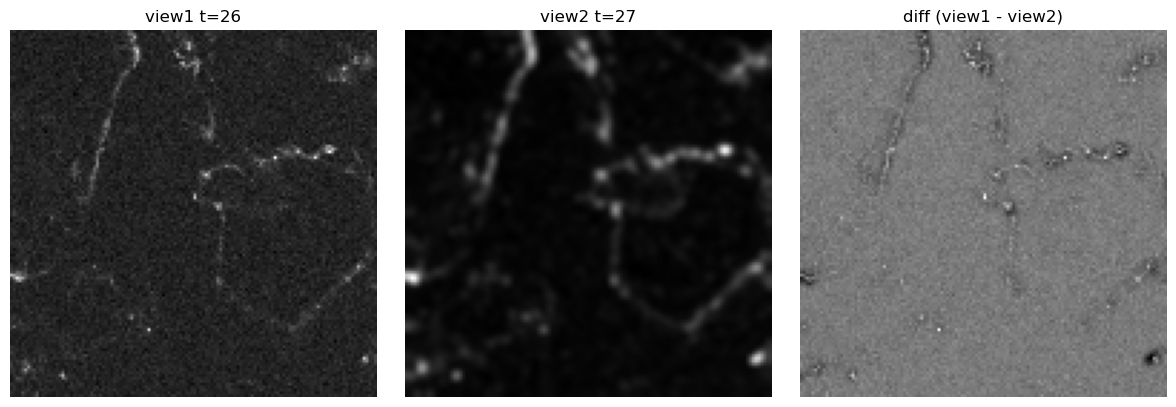

In [2]:
# Cell 2 — pull one positive pair, show view1 / view2 / diff, print metadata.
import matplotlib.pyplot as plt

pair = next(iter(ds))
v1 = pair['view1'][0].numpy()
v2 = pair['view2'][0].numpy()
meta = pair['meta']
print('meta:', meta)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, title in zip(
    axes,
    (v1, v2, v1 - v2),
    (f"view1 t={meta['t1']}", f"view2 t={meta['t2']}", 'diff (view1 - view2)'),
):
    ax.imshow(img, cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout(); plt.show()


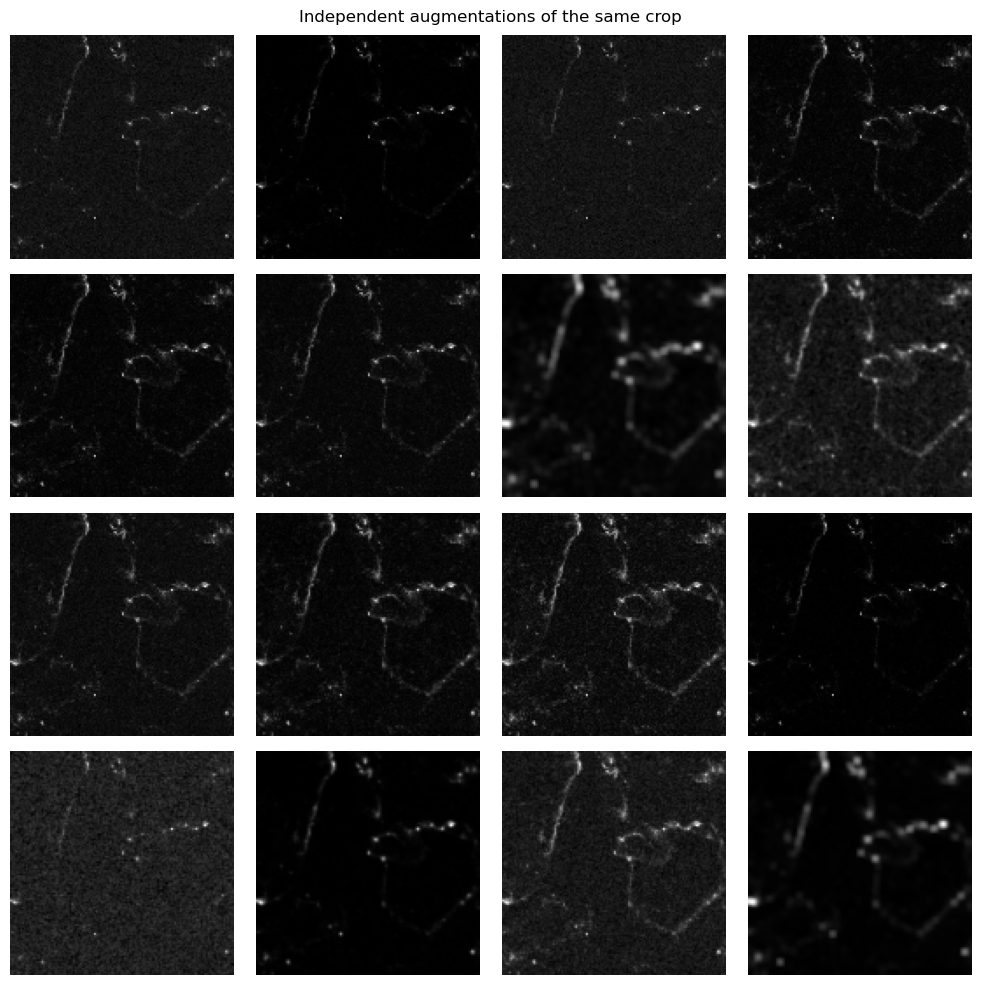

In [3]:
# Cell 3 — 4x4 grid of independently augmented variants of the SAME raw crop.
import numpy as np
import torch
import matplotlib.pyplot as plt
from data.augmentations import build_augmentations

# Use the first view of the pair from Cell 2 as the base crop, BEFORE augs.
# We reconstruct an un-augmented base by re-loading the same crop directly.
m = meta
slice_h = cfg.crop_size * ds.runtime_downsample
slice_w = cfg.crop_size * ds.runtime_downsample
base = ds._load_crop(int(m['t1']), int(m['z']), int(m['y']), int(m['x']), slice_h, slice_w)

augment = build_augmentations(cfg)

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for ax in axes.flat:
    out = augment(base.clone())[0].numpy()
    ax.imshow(out, cmap='gray')
    ax.axis('off')
plt.suptitle('Independent augmentations of the same crop')
plt.tight_layout(); plt.show()


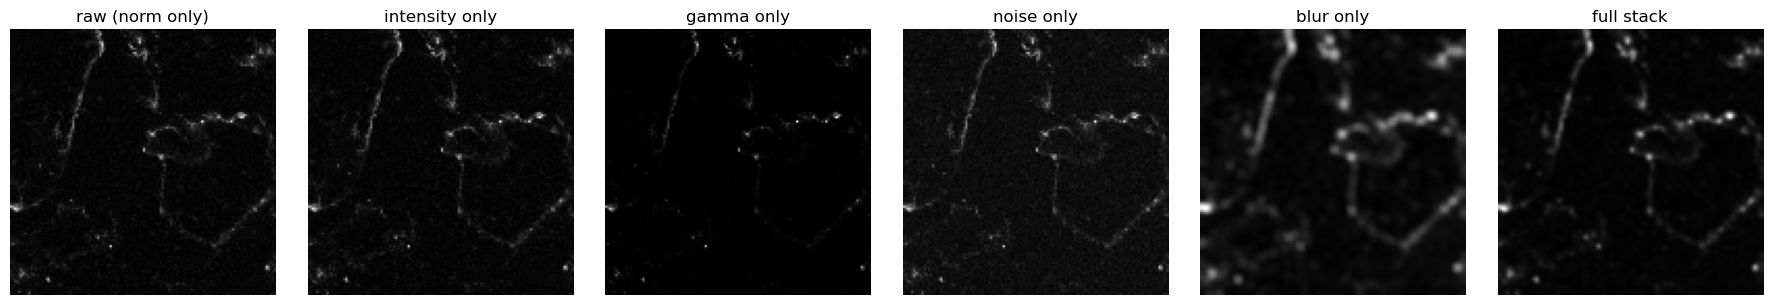

In [4]:
# Cell 4 — per-augmentation isolation. Show base, intensity-only, gamma-only,
# noise-only, blur-only, and full stack.
from dataclasses import replace
import copy
import matplotlib.pyplot as plt

def isolate(name):
    c = copy.deepcopy(cfg)
    for attr in ('aug_intensity', 'aug_gamma', 'aug_noise', 'aug_blur'):
        getattr(c, attr).enabled = (attr == name)
    # Always keep per-crop norm so visual ranges are comparable.
    c.aug_percrop_norm.enabled = True
    # Force application this run (p=1.0) for a clear demo.
    if name in ('aug_intensity','aug_gamma','aug_noise','aug_blur'):
        getattr(c, name).p = 1.0
    return build_augmentations(c)

configs = [
    ('raw (norm only)', None),
    ('intensity only', 'aug_intensity'),
    ('gamma only', 'aug_gamma'),
    ('noise only', 'aug_noise'),
    ('blur only', 'aug_blur'),
    ('full stack', 'all'),
]
fig, axes = plt.subplots(1, len(configs), figsize=(3*len(configs), 3))
for ax, (title, key) in zip(axes, configs):
    if key is None:
        c = copy.deepcopy(cfg)
        for a in ('aug_intensity','aug_gamma','aug_noise','aug_blur'):
            getattr(c, a).enabled = False
        aug = build_augmentations(c)
    elif key == 'all':
        aug = build_augmentations(cfg)
    else:
        aug = isolate(key)
    out = aug(base.clone())[0].numpy()
    ax.imshow(out, cmap='gray'); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()


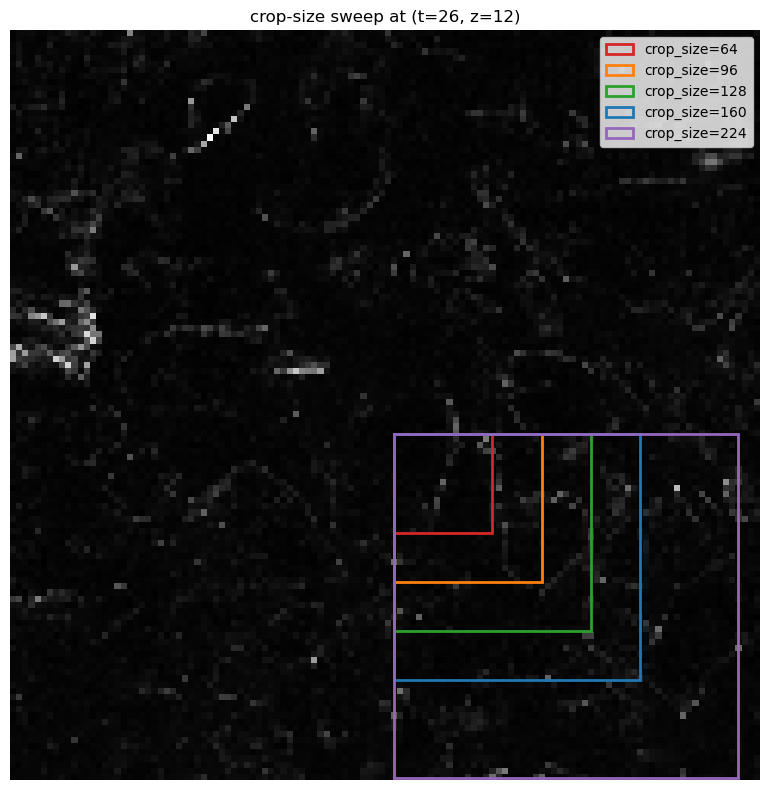

In [5]:
# Cell 5 — crop-size sweep on one anchor; overlay rectangles on a downsampled frame.
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import torch.nn.functional as F
import torch

# Pull the full Y x X frame at (t1, z) and downsample for display.
frame = ds.arr[int(meta['t1']), cfg.channel, int(meta['z']), :, :].compute()
frame = np.asarray(frame, dtype=np.float32)
frame = np.clip(frame, 0, cfg.max_intensity) / cfg.max_intensity

display_ds = 4
disp = torch.from_numpy(frame).unsqueeze(0).unsqueeze(0)
disp = F.interpolate(disp, scale_factor=1/display_ds, mode='bilinear', align_corners=False)
disp = disp.squeeze().numpy()

x_off = int(meta['x']); y_off = int(meta['y'])
sizes = [64, 96, 128, 160, 224]
colors = ['tab:red','tab:orange','tab:green','tab:blue','tab:purple']

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(disp, cmap='gray')
for s, c in zip(sizes, colors):
    slice_px = s * ds.runtime_downsample  # at original-array scale
    rect = patches.Rectangle(
        (x_off / display_ds, y_off / display_ds),
        slice_px / display_ds, slice_px / display_ds,
        linewidth=2, edgecolor=c, facecolor='none', label=f'crop_size={s}',
    )
    ax.add_patch(rect)
ax.legend(loc='upper right')
ax.set_title(f'crop-size sweep at (t={int(meta["t1"])}, z={int(meta["z"])})')
ax.axis('off')
plt.tight_layout(); plt.show()


In [ ]:
# Cell 6 (optional) — napari view of a full positive pair with metadata overlay.
# Requires napari to be installed and a display.
try:
    import napari
    pair = next(iter(ds))
    v1 = pair['view1'][0].numpy()
    v2 = pair['view2'][0].numpy()
    viewer = napari.Viewer()
    viewer.add_image(v1, name=f"view1 t={int(pair['meta']['t1'])}")
    viewer.add_image(v2, name=f"view2 t={int(pair['meta']['t2'])}")
    viewer.text_overlay.visible = True
    viewer.text_overlay.text = (
        f"t1={int(pair['meta']['t1'])} t2={int(pair['meta']['t2'])} "
        f"z={int(pair['meta']['z'])} x={int(pair['meta']['x'])} y={int(pair['meta']['y'])}"
    )
    napari.run()
except ImportError:
    print('napari not installed; skipping interactive view.')


napari not installed; skipping interactive view.


: 